# PlantMetwiki metabolites vs. NPClassifier Classifications

**Question:** What is the coverage of the classifications of [NPClassifier](https://npclassifier.gnps2.org) for the metabolites in [PlantMetWiki](https://plantmetwiki.bioinformatics.nl)? 

**Approach:**
- For each metabolite annotated with an InChiKey collect the SMILES
- For each Metabolite for which a SMILES was obtained collect the NPClassifier classification at pathway, superclass and class level if present.
- Annalyse the coverage at all three levels of the NPClassifier classification


## Python packages
In the code bellow python packages are imported as needed

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

## Load in PlantMetWiki dataset
This PlantMetWiki dataset contains all metabolites in PlantMetWiki

In [286]:
## Load in the PlantMetWiki data from the CSV
# df_plant_met_wiki = pd.read_csv("./data/plantmetwiki_metabolites.csv")

## subset data if required
# InChiKey_full = df_plant_met_wiki

# InChiKey_full.head()

# 2. InChIKeys to SMILES

In the code bellow Inchikeys are converted to SMILES ussing the [PubChem](https://pubchem.ncbi.nlm.nih.gov) database. Note some Metabolites have no know SMILES in [PubChem](https://pubchem.ncbi.nlm.nih.gov), these metabolites will have NaN.


In [ ]:
# counting the NaN, these Inchikeys have no SMILES linked in Pubchem
no_smiles = InChiKey_full["smiles"].isna().sum()
print(no_smiles)


0


In [ ]:
def key_to_smiles(inchikey):
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/inchikey/%s/property/IsomericSMILES/TXT" % inchikey
    response = requests.get(url, timeout=30)
    smiles = response.text.strip()
    if smiles.startswith('Status: 404'):
        smiles = None
    return smiles

In [ ]:
# InChiKey_full["smiles"] = InChiKey_full["inchikey"].apply(key_to_smiles)
# InChiKey_full.columns

Index(['inchikey', 'name', 'wikidata', 'n_pathways', 'smiles'], dtype='str')

# 3. SMILES to NPClassifier classifiation
In the code below all metabolites with a SMILES are classified using the NPClassifier (v1.5) website as adapted from the example query provided in the suplementary materials of Kim, H. et al (2021). 




In [320]:
def smiles_to_NPCs(smiles):
    if smiles != None:
            url = f"https://npclassifier.gnps2.org/classify?smiles=%s" %smiles
            response = requests.get(url, timeout = 30)
            if response.status_code != 200:
                             path = None
                             super = None
                             sub = None  
            else: 
                pathway = response.json()["pathway_results"]
                superclass = response.json()["superclass_results"]
                subclass = response.json()["class_results"]

                if len(pathway) == 1:
                    path = pathway[0] 
                else:
                    path = None

                if len(superclass) == 1:
                    super = superclass[0] 
                else:
                    super = None

                if len(subclass) == 1:
                    sub = subclass[0]
                else:
                    sub = None  
    else:
         path = None
         super = None
         sub = None  
    return path, super, sub

def split_ncp_class_in_path(ncp_classification):
    path, super, sub = ncp_classification
    return path

def split_ncp_class_in_superclass(ncp_classification):
    path, super, sub = ncp_classification
    return super

def split_ncp_class_in_class(ncp_classification):
    path, super, sub = ncp_classification
    return sub



In [321]:

# # Gather NPC clasification
# InChiKey_full["ncp_classification"] = InChiKey_full["smiles"].apply(smiles_to_NPCs)

# #split NPC clasfication into 3 collumns
# InChiKey_full["ncp_pathway"] = InChiKey_full["ncp_classification"].apply(split_ncp_class_in_path)
# InChiKey_full["ncp_superclass"] = InChiKey_full["ncp_classification"].apply(split_ncp_class_in_superclass)
# InChiKey_full["ncp_class"] = InChiKey_full["ncp_classification"].apply(split_ncp_class_in_class)

In [322]:
# Write data To CSV file
InChiKey_full.to_csv("All_NPC_classifications.csv", index=True, header=True)

# 4. Coverage Calculations
In the code below an overage of the coverage of NPC metabolites at different levels of clasification is calculated and discussed.

In [316]:
#Coverage by counts
Metabolites_keys= InChiKey_full["inchikey"].count()
Metabolites_smiles = InChiKey_full["smiles"].count()
Metabolites_pathway =InChiKey_full["ncp_pathway"].count()
Metabolites_superclass =InChiKey_full["ncp_superclass"].count()
Metabolites_class = InChiKey_full["ncp_class"].count()

print(f"Number of metabolites checked : {Metabolites_keys} \nNumber of metabolites who have a SMILES: {Metabolites_smiles}\nNumber of metabolites who have A NPClassifier pathway classification: {Metabolites_pathway} \nNumber of metabolites who have A NPClassifier superclass classification: {Metabolites_superclass} \nNumber of metabolites who have A NPClassifier class classification: {Metabolites_class}")

Number of metabolites checked : 2974 
Number of metabolites who have a SMILES: 2889
Number of metabolites who have A NPClassifier pathway classification: 2324 
Number of metabolites who have A NPClassifier superclass classification: 2178 
Number of metabolites who have A NPClassifier class classification: 1953


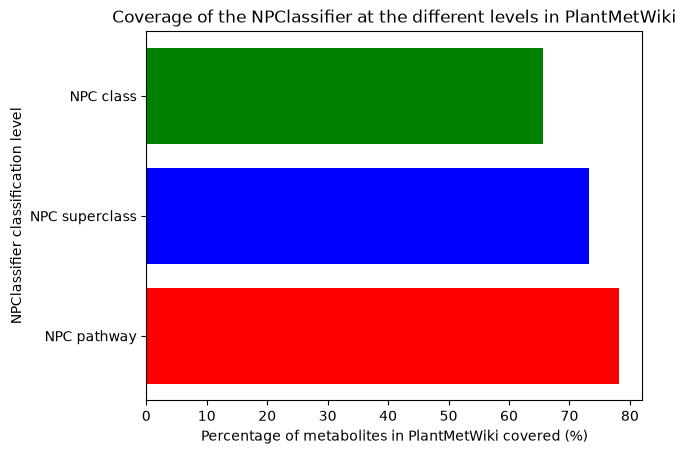

In [319]:
#coverage by percentages
smiles_coverage = Metabolites_smiles/Metabolites_keys * 100
NPC_pathway_coverage = Metabolites_pathway/Metabolites_keys * 100
NPC_superclass_coverage = Metabolites_superclass/Metabolites_keys * 100
NPC_class_coverage = Metabolites_class/Metabolites_keys * 100

plt.barh( ["NPC pathway", "NPC superclass", "NPC class"], [NPC_pathway_coverage, NPC_superclass_coverage, NPC_class_coverage], color = ['red', 'blue', 'green'])
plt.title("Coverage of the NPClassifier at the different levels in PlantMetWiki")
plt.xlabel("Percentage of metabolites in PlantMetWiki covered (%)")
plt.ylabel("NPClassifier classification level")
plt.show()


Interpetation:
- Less then 80% of the metabolites in PlantMetWiki who have an annotated InChIKey are (partially) covered with an NPClasifier classification.
- Coverage NPClassifier classification lower with the increase of specifiity of the annotations.
- NPClassifier levels are named pathway, superclass and class. Be aware that these terms are not the \ interchangable with terms as one might refer to in metabolomics.
- NPClassifiers covers all chemical compounds not just metabolites, but also protiens.
- If NPClassifier terms would be integrated with the PLantMetWiki database almost a third of the metabolites will not have a class level classification.



# 5. Run-Time.

The WikiPathway set contains circa 3000 metabolites as of 12 november 2026, of thesse metabolites 2974 have an InChikey annotation.

As this Notebook uses a query to collect a metabolites SMILES and NPClassifier classification. We have made an over view of the average runtimes based on the amount of metabolite inputed. For both searches the runtime has been capped at 30 seconds, if it takes longer then 30 seconds to find something the assumption is made that there is nothing to find, thus the SMILES or NPClassifier classification is set to None. Worse case scenario, al seaches go the full time for a combined 60 seconds. In that scenario a 3000 metabolite search would take 50 hours. 

For a subset of 10 metabolites it took 40 seconds to gather the SMILES and another 60 seconds to run the NPClassifier classification. (worse case: 10 minutes) 
For a subset of 100 metabolites it took 40 seconds to gather the SMILES and another 60 seconds to run the NPClassifier classification. (worse case: 1 hour and 40 minutes)
For a subset of 1000 Metabolites it  took 6 minutes and 6 seconds to collect the SMILES and 9 minutes and 11 seconds to collect the NPClassifier classification. (worse case: 17 hours)
For a subset of 1000 Metabolites It takes 17 minutes to collect teh SMILES and 28 minutes to collect the NPClassifier classification. (worse case: 50 hours)

# 6.References

Kim, H. W., Wang, M., Leber, C. A., Nothias, L. F., Reher, R., Kang, K. B., van der Hooft, J. J. J., Dorrestein, P. C., Gerwick, W. H., & Cottrell, G. W. (2021). NPClassifier: A Deep Neural Network-Based Structural Classification Tool for Natural Products. Journal of natural products, 84(11), 2795–2807. https://doi.org/10.1021/acs.jnatprod.1c00399